## Simulação - Tetraedro Gerado Aleatoriamente numa Esfera
### SME0123 - Estatística
---
* **Docente:** Eduardo Fontoura Costa
* **Monitor:** Luiz Henrique Romero
* **Alunos:** Pedro Henrique de Sousa Prestes (15507819), João Gabriel Pieroli da Silva (15678578) e Luysa de Souza Gonçalves (15474077)
---

In [1]:
# Setup
%pip install numpy plotly nbformat scipy pandas -q

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import matplotlib.pyplot as plt
from scipy import stats

SEED = 4545
np.random.seed(SEED)

Note: you may need to restart the kernel to use updated packages.


### Introdução
Sorteie 4 pontos ao acaso numa esfera de raio $R$, e considere o tetraedro formado por eles, como na Figura 1 abaixo. Qual a chance de o centro da esfera estar contido no tetraedro?

In [2]:
# Definição de parâmetros para a figura
R = 1 # Raio arbitrário
theta = np.linspace(0, 2 * np.pi, 50)
phi = np.linspace(0, np.pi, 50)
THETA, PHI = np.meshgrid(theta, phi)

X = R * np.sin(PHI) * np.cos(THETA)
Y = R * np.sin(PHI) * np.sin(THETA)
Z = R * np.cos(PHI)
###

# Criando a figura com plotly para interação
fig = go.Figure()

fig.add_trace(go.Surface(
    x=X, y=Y, z=Z,
    colorscale='Blues',   # Cor da esfera
    opacity=0.7,
    showscale=False,      # Remove a barra de cores lateral
    name='Esfera'
))

p = np.random.randn(4, 3)
p /= np.linalg.norm(p, axis=1)[:, np.newaxis]
fig.add_trace(go.Mesh3d(
    x=p[:, 0], y=p[:, 1], z=p[:, 2],
    i = [0, 0, 0, 1], j = [1, 1, 2, 2], k = [2, 3, 3, 3],
    color='orange',
    opacity=0.5,        # Transparência para ver através
    flatshading=True,   # Deixa as faces "duras" (sem suavizar a luz)
    name='Tetraedro'
))

fig.add_trace(go.Scatter3d(
    x=p[:, 0], y=p[:, 1], z=p[:, 2],
    mode='markers',       # Define que são apenas pontos, sem linhas
    marker=dict(
        size=4,           # Tamanho da bolinha
        color='red',      # Cor
        opacity=0.8       # Transparência do ponto
    ),
    name='Pontos'
))

fig.update_layout(
    title='Figura 1',
    autosize=False,
    width=600, height=600,
    scene=dict(
        aspectmode='data', # Força proporção 1:1:1 (esfera perfeita)
        xaxis_title='X',
        yaxis_title='Y',
        zaxis_title='Z',
    ),
)

fig.show()

Simulamos 4 pontos obedecendo um modelo, verificamos se houve sucesso nesta primeira simulação, marcamos $X_1$ = 1 no caso de sucesso ou $X_1 = 0$ para fracasso. Repetimos isso $N$ vezes e estimamos $p$ assim:
$$\hat{p_N} = \bar{X_N} = \frac{X_1 + ... + X_N}{N}$$

### Atividade 1
Gere mil pontos aleatoriamente na esfera e trace um gráfico dos pontos gerados. Inspecione se os pontos estão uniformemente distribuidos pela superfície da esfera.

In [3]:
n_points = 1000

# Gerar direções aleatórias uniformes
p = np.random.randn(n_points, 3) # Gaussiana ao invés de uniforme
p /= np.linalg.norm(p, axis=1)[:, np.newaxis]

fig = go.Figure()
fig.add_trace(go.Surface(
    x=X, y=Y, z=Z,
    colorscale='Blues',   # Cor da esfera
    opacity=0.7,
    showscale=False,      # Remove a barra de cores lateral
    name='Esfera'
))

fig.add_trace(go.Scatter3d(
    x=p[:, 0], y=p[:, 1], z=p[:, 2],
    mode='markers',       # Define que são apenas pontos, sem linhas
    marker=dict(
        size=4,           # Tamanho da bolinha
        color='red',      # Cor
        opacity=0.8       # Transparência do ponto
    ),
    name='Pontos Aleatórios'
))

fig.update_layout(
    title='Esfera com Pontos Aleatórios',
    autosize=False,
    width=600, height=600,
    scene=dict(
        aspectmode='data', # Força proporção 1:1:1 (esfera perfeita)
        xaxis_title='X',
        yaxis_title='Y',
        zaxis_title='Z',
    )
)

fig.show()

Utilizando **Qui-Quadrado ($\chi^2$)** para estimar se os pontos estão distribuídos uniformemente formalmente ao longo do eixo $z$. 

In [4]:
n_bins = 20

z = p[:, 2] # Pegamos apenas a altura Z
    
# 1. Definir os intervalos (bins)
bins = np.linspace(-R, R, n_bins + 1)
    
# 2. Contar quantos pontos caíram em cada fatia (Observado)
contagem_observada, _ = np.histogram(z, bins=bins)
    
# 3. Definir o Esperado
# Se for uniforme, cada bin deve ter N_total / n_bins pontos
contagem_esperada = np.full(n_bins, n_points / n_bins)
    
# 4. Calcular o Qui-Quadrado
# A função retorna a estatística e o p-valor
chi2_stat, p_value = stats.chisquare(f_obs=contagem_observada, f_exp=contagem_esperada)

chi2_stat, p_value

(np.float64(18.64), np.float64(0.48013899649640757))

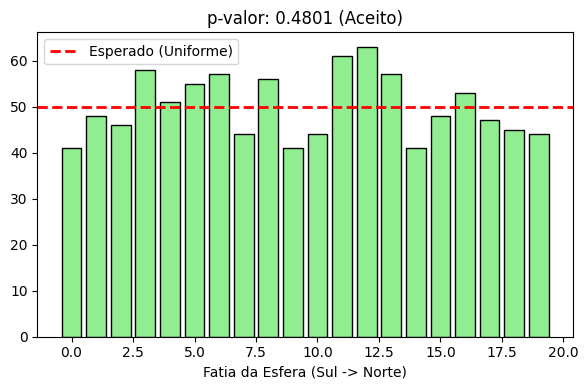

   -> CONCLUSÃO: Distribuição uniforme aceita (Não há evidência de viés).


In [5]:
# Resultados e Visualização
fig = plt.figure(figsize=(6,4))

esperado = n_points / n_bins
plt.bar(range(n_bins), contagem_observada, color='lightgreen', edgecolor='black')
plt.axhline(esperado, color='red', linestyle='--', linewidth=2, label='Esperado (Uniforme)')
plt.title(f"p-valor: {p_value:.4f} (Aceito)")
plt.xlabel("Fatia da Esfera (Sul -> Norte)")
plt.legend()

plt.tight_layout()
plt.show()

if p_value < 0.05:
    print("   -> CONCLUSÃO: A distribuição NÃO é uniforme.")
else:
    print("   -> CONCLUSÃO: Distribuição uniforme aceita (Não há evidência de viés).")

### Atividade 2
Para os pontos gerados, construa $N = 250$ tetraedros e calcule $\hat{p}_N$ para cada um deles.

In [6]:
def contem_origem(pontos: np.array) -> bool:
    """
    Verifica se a origem (0,0,0) está dentro do tetraedro formado por 4 pontos.
    pontos: Array numpy shape (4, 3)
    Retorna: True se dentro, False se fora.
    """
    # Montamos a matriz A transposta (colunas são os pontos)
    # Adicionamos uma linha de 1s no final para garantir a soma c = 1
    # Matriz 4x4:
    # [ x0  x1  x2  x3 ]
    # [ y0  y1  y2  y3 ]
    # [ z0  z1  z2  z3 ]
    # [ 1   1   1   1  ]
    
    # .T faz a transposta (linhas viram colunas)
    matriz_sistema = np.vstack([pontos.T, np.ones(4)])
    
    # O alvo é (0, 0, 0, 1)
    vetor_alvo = np.array([0, 0, 0, 1])
    
    try:
        # Resolvemos o sistema linear para achar os coeficientes (pesos)
        coeficientes = np.linalg.solve(matriz_sistema, vetor_alvo)
        
        # Se TODOS os coeficientes forem positivos, a origem está dentro (ou na borda se >= 0)
        # Usamos uma tolerância pequena (1e-8) por causa de erros de arredondamento do float
        return np.all(coeficientes > -1e-8)
        
    except np.linalg.LinAlgError:
        # Se a matriz for singular, os pontos são coplanares (tetraedro achatado)
        # Volume zero não contém a origem 3D
        return False

In [7]:
# Vamos garantir que usamos apenas grupos completos de 4
n_amostras = len(p) // 4 

# De (N, 3) para (N/4, 4, 3) -> Uma lista de Matrizes 4x3
grupos_tetraedros = p[:n_amostras * 4].reshape(n_amostras, 4, 3)
resultados = [contem_origem(grupo) for grupo in grupos_tetraedros]

# Calcular a média
# sum(True) conta como 1, sum(False) conta como 0
probabilidade = sum(resultados) / n_amostras

print(f"-> Total de Tetraedros testados: {n_amostras}")
print(f"-> Média (Probabilidade): {probabilidade:.4f}")

-> Total de Tetraedros testados: 250
-> Média (Probabilidade): 0.1440


### Atividade 3
Repita, gerando mais pontos, para construir $N = 10^3, N = 10^4, N = 10^5, N = 10^6 e N = 10^7$ tetraedros. Gere uma tabela com os resultados obtidos.

In [8]:
def calcular_media(n_amostras: int) -> float:
    """
    Calcula a média de ocorrências do centro contido no tetraedro
    n_amostras: Quantidade de tetraedros gerados
    Retorna: Probabilidade do centro estar contido.
    """
    p = np.random.randn(n_amostras * 4, 3)
    p /= np.linalg.norm(p, axis=1)[:, np.newaxis]
    
    grupos_tetraedros = p[:n_amostras * 4].reshape(n_amostras, 4, 3)
    resultados = [contem_origem(grupo) for grupo in grupos_tetraedros]
    return sum(resultados) / n_amostras

col_prob = [calcular_media(n_amostras) for n_amostras in [1000, 10000, 100000, 1000000, 10000000]]

pd.DataFrame({'Qtd. Amostras': ['10³', '10⁴', '10⁵', '10⁶', '10⁷'], 'Probabilidades': col_prob})

,Qtd. Amostras,Probabilidades
0,10³,0.119000
1,10⁴,0.125100
2,10⁵,0.124310
3,10⁶,0.125014
4,10⁷,0.125040


### Atividade 4
Dê o resultado para $p$ na forma de um intervalo de confiança.

In [9]:
alfa = 0.05
p = 0.1250
n = 10000000

erro = stats.norm.ppf(1 - alfa/2) * np.sqrt((p * (1-p)) / n)
print(f"IC: {np.array([p - erro, p + erro]).round(4)}")

IC: [0.1248 0.1252]
